## 1. 라이브러리 임포트

데이터셋 로드에 필요한 라이브러리를 불러옵니다.
- `torch`: 텐서 연산
- `torchvision.datasets`: FashionMNIST 데이터셋 제공
- `torchvision.transforms`: 이미지를 텐서로 변환
- `numpy`: 배열 기반 수치 계산 (EDA 통계)
- `matplotlib`: 이미지 및 그래프 시각화 (EDA)
- `sys`: 실행 중인 Python 버전 확인

In [1]:
import sys

import torch
import torchvision
import torchvision.transforms as transforms
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# 실행 환경의 버전 확인 (팀원 간 환경 차이로 오류가 생겼을 때 원인 파악용)
print(f"Python      : {sys.version.split()[0]}")
print(f"torch       : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"numpy       : {np.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")

Python      : 3.12.14
torch       : 2.14.1+cu130
torchvision : 0.29.1+cu130
numpy       : 2.5.4
matplotlib  : 3.11.2


## 2. FashionMNIST 데이터셋 불러오기

FashionMNIST는 10개 의류 클래스로 구성된 28×28 흑백 이미지 데이터셋입니다.
- 학습 데이터: 60,000장
- 테스트 데이터: 10,000장

- 클래스 목록:
    - T-shirt/top
    - Trouser
    - Pullover
    - Dress
    - Coat
    - Sandal
    - Shirt
    - Sneaker
    - Bag
    - Ankle boot

EDA 결과를 해석하기 쉽도록, 이 단계에서는 `ToTensor()`만 적용합니다.
`ToTensor()`는 0~255 정수 픽셀을 255로 나눠 0.0~1.0 실수로 바꿉니다.
생성 모델 학습에 필요한 정규화는 이후 전처리 단계에서 별도로 적용합니다.

데이터는 레포 규칙(`data/README.md`)에 따라 레포 최상위의 `data/raw/`에 저장합니다.
노트북이 `eda/` 폴더에 있으므로 상대 경로 `../data/raw`를 사용합니다.

In [2]:
# 데이터셋을 저장할 경로 (없으면 자동 생성)
DATA_ROOT = '../data/raw'

# PIL 이미지(uint8, 0~255) → FloatTensor(0.0~1.0), shape: (채널=1, 높이=28, 너비=28)
eda_transform = transforms.ToTensor()

# 학습 데이터셋 (train=True) - 로컬에 없으면 다운로드
train_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=True,
    download=True,
    transform=eda_transform
)

# 테스트 데이터셋 (train=False)
test_dataset = torchvision.datasets.FashionMNIST(
    root=DATA_ROOT,
    train=False,
    download=True,
    transform=eda_transform
)

## 3. 데이터셋 로드 결과 확인

데이터가 정상적으로 로드되었는지 간단히 확인합니다.
- 학습/테스트 데이터 개수
- 샘플 1개의 shape, 자료형, 픽셀 값 범위
- 클래스 인덱스와 클래스 이름의 매핑 (이후 EDA와 시각화에서 사용)

In [3]:
# 데이터 개수 확인
print(f"학습 데이터 개수  : {len(train_dataset):,}")
print(f"테스트 데이터 개수: {len(test_dataset):,}")

# 첫 번째 샘플로 변환 결과 확인
img, label = train_dataset[0]
print(f"\n이미지 shape : {tuple(img.shape)}")   # (1, 28, 28) 예상
print(f"이미지 dtype : {img.dtype}")            # torch.float32 예상
print(f"픽셀 값 범위 : [{img.min().item():.3f}, {img.max().item():.3f}]")  # 0~1 사이 예상
print(f"레이블       : {label} ({train_dataset.classes[label]})")

# 클래스 인덱스 → 클래스 이름 매핑
idx_to_class = {i: name for i, name in enumerate(train_dataset.classes)}
idx_to_class

학습 데이터 개수  : 60,000
테스트 데이터 개수: 10,000

이미지 shape : (1, 28, 28)
이미지 dtype : torch.float32
픽셀 값 범위 : [0.000, 1.000]
레이블       : 9 (Ankle boot)


{0: 'T-shirt/top',
 1: 'Trouser',
 2: 'Pullover',
 3: 'Dress',
 4: 'Coat',
 5: 'Sandal',
 6: 'Shirt',
 7: 'Sneaker',
 8: 'Bag',
 9: 'Ankle boot'}

## 4. 클래스(옷 종류)별 이미지 개수 확인

옷 종류마다 이미지가 몇 장씩 있는지 직접 세어 확인합니다.

### 방법
- 학습/테스트 데이터셋에서 `targets` 속성의 값을 꺼내, 값별로 개수를 셉니다.
- 이 값이 각 이미지의 클래스 번호인지는 결과로 확인합니다.
  - 값별 개수의 합계가 이미지 수(학습 60,000 / 테스트 10,000)와 같은가?
  - 값이 클래스 번호 범위(0~9) 안에 있는가?
- 결과는 표(정확한 숫자)와 막대그래프(한눈에 비교)로 확인합니다.
  - 학습과 테스트는 전체 규모가 달라서, 그래프를 두 개로 나눠 그립니다.
  - 그래프 안의 글자는 한글이 깨지지 않도록 영어로 표시합니다.

### 확인할 점
- 클래스마다 개수가 고르게 나뉘어 있는가?

No  Class          Train  Train %    Test  Test %
-------------------------------------------------
 0  T-shirt/top    6,000    10.0%   1,000   10.0%
 1  Trouser        6,000    10.0%   1,000   10.0%
 2  Pullover       6,000    10.0%   1,000   10.0%
 3  Dress          6,000    10.0%   1,000   10.0%
 4  Coat           6,000    10.0%   1,000   10.0%
 5  Sandal         6,000    10.0%   1,000   10.0%
 6  Shirt          6,000    10.0%   1,000   10.0%
 7  Sneaker        6,000    10.0%   1,000   10.0%
 8  Bag            6,000    10.0%   1,000   10.0%
 9  Ankle boot     6,000    10.0%   1,000   10.0%
-------------------------------------------------
    Total         60,000   100.0%  10,000  100.0%


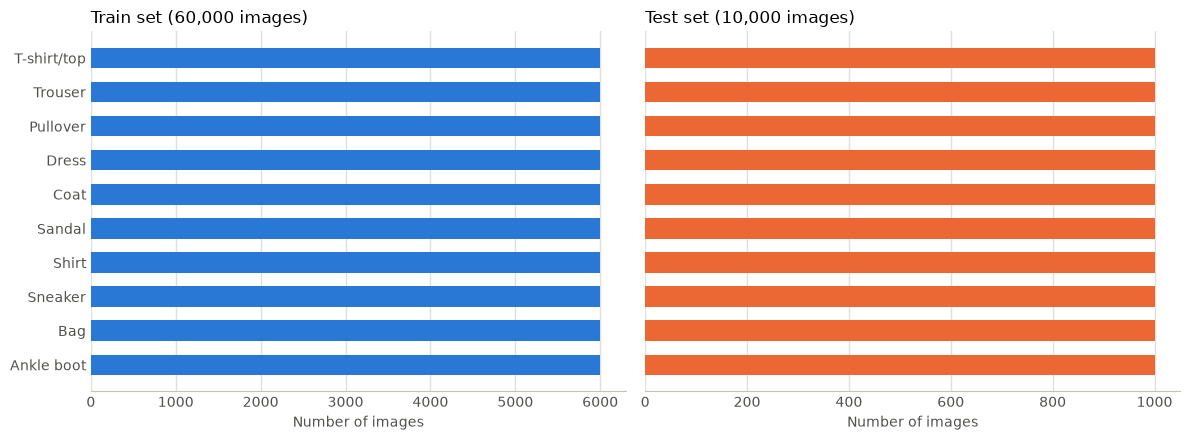

In [4]:
# 4-1. 학습/테스트 데이터셋의 targets 값 꺼내기
#  - 이미지를 한 장씩 불러오지 않고 targets 값만 한 번에 꺼냅니다.
#  - 이 값이 각 이미지의 클래스 번호인지는 아래 표의 결과(합계, 값 범위)로 확인합니다.
train_labels = train_dataset.targets.numpy()
test_labels = test_dataset.targets.numpy()

class_names = train_dataset.classes   # ['T-shirt/top', 'Trouser', ...]
num_classes = len(class_names)        # 10

# 4-2. 클래스별 개수 세기
#  - np.bincount: 0, 1, 2, ... 각 번호가 몇 번 나오는지 셉니다.
#  - minlength=num_classes: 개수가 0인 클래스가 있어도 결과 길이를 10으로 맞춥니다.
train_counts = np.bincount(train_labels, minlength=num_classes)
test_counts = np.bincount(test_labels, minlength=num_classes)

# 4-3. 표로 출력 (클래스별 개수 + 전체 대비 비율)
print(f"{'No':>2}  {'Class':<12} {'Train':>7} {'Train %':>8} {'Test':>7} {'Test %':>7}")
print("-" * 49)
for i, name in enumerate(class_names):
    train_ratio = train_counts[i] / train_counts.sum() * 100
    test_ratio = test_counts[i] / test_counts.sum() * 100
    print(f"{i:>2}  {name:<12} {train_counts[i]:>7,} {train_ratio:>7.1f}% "
          f"{test_counts[i]:>7,} {test_ratio:>6.1f}%")
print("-" * 49)
print(f"{'':>2}  {'Total':<12} {train_counts.sum():>7,} {'100.0%':>8} "
      f"{test_counts.sum():>7,} {'100.0%':>7}")

# 4-4. 막대그래프로 시각화
#  - 학습/테스트는 전체 개수 규모가 달라서(60,000 vs 10,000) 그래프를 두 개로 나눠 그립니다.
#  - 클래스 이름이 길어서 가로 막대그래프(barh)를 사용합니다.
#  - 그래프 안의 글자는 영어로 씁니다. (matplotlib 기본 글꼴은 한글이 깨져서 보이기 때문)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, counts, title, color in zip(
    axes,
    [train_counts, test_counts],
    [f"Train set ({train_counts.sum():,} images)", f"Test set ({test_counts.sum():,} images)"],
    ["#2a78d6", "#eb6834"],   # 학습: 파란색, 테스트: 주황색
):
    ax.barh(range(num_classes), counts, color=color, height=0.6)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Number of images", color="#52514e")
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)   # 옅은 세로 보조선
    ax.set_axisbelow(True)                            # 보조선을 막대 뒤로 보내기
    for side in ["top", "right", "left"]:             # 불필요한 테두리 제거
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(colors="#52514e", length=0)

axes[0].set_yticks(range(num_classes))
axes[0].set_yticklabels(class_names)
axes[0].invert_yaxis()   # 0번 클래스가 맨 위에 오도록 순서 뒤집기

plt.tight_layout()
plt.show()

### 결과
- 학습 데이터: 10개 클래스 모두 6,000장씩(각 10.0%)이고, 합계는 60,000장입니다.
- 테스트 데이터: 10개 클래스 모두 1,000장씩(각 10.0%)이고, 합계는 10,000장입니다.
- 막대그래프에서도 학습/테스트 모두 클래스마다 막대 길이가 같습니다.

### 해석
- `targets` 값이 각 이미지의 클래스 번호인가?
  - 값별 개수의 합계(학습 60,000 / 테스트 10,000)가 셀 3에서 확인한 이미지 수와 같습니다. 이미지마다 `targets` 값이 하나씩 있다는 뜻입니다.
  - 0~9번 개수를 모두 더한 값이 전체 합계와 같으므로, 0~9 밖의 값은 없습니다.
  - 두 기준을 모두 만족하므로, 이후 단계에서는 `targets` 값을 각 이미지의 클래스 번호로 사용합니다. 번호와 실제 이미지가 맞는지는 셀 5에서 이미지로 확인합니다.
- 클래스마다 개수가 고르게 나뉘어 있는가?
  - 학습/테스트 모두 모든 클래스의 개수가 같아, 클래스 간 개수 차이(불균형)가 없습니다.

## 5. 클래스별 샘플 이미지 확인

옷 종류마다 실제 이미지가 어떻게 생겼는지 눈으로 확인합니다.

### 방법
- 셀 4에서 꺼낸 학습 데이터의 `targets` 값을 기준으로, 클래스마다 5장씩 무작위로 골라 10줄 × 5칸으로 보여줍니다.
- 랜덤 시드(`SEED = 42`)를 고정해서, 다시 실행하거나 팀원이 실행해도 같은 이미지가 나오도록 합니다.
- 데이터셋의 `data` 속성에 저장된 이미지를 흑백으로 표시합니다.
  - 모든 이미지의 밝기 기준을 같게 하기 위해 표시 범위를 0~255로 고정합니다.

### 확인할 점
- 옷 종류마다 어떻게 생겼는가?
- 서로 헷갈릴 만큼 비슷한 종류가 있는가?
- 같은 종류 안에서도 모양이 얼마나 다양한가?

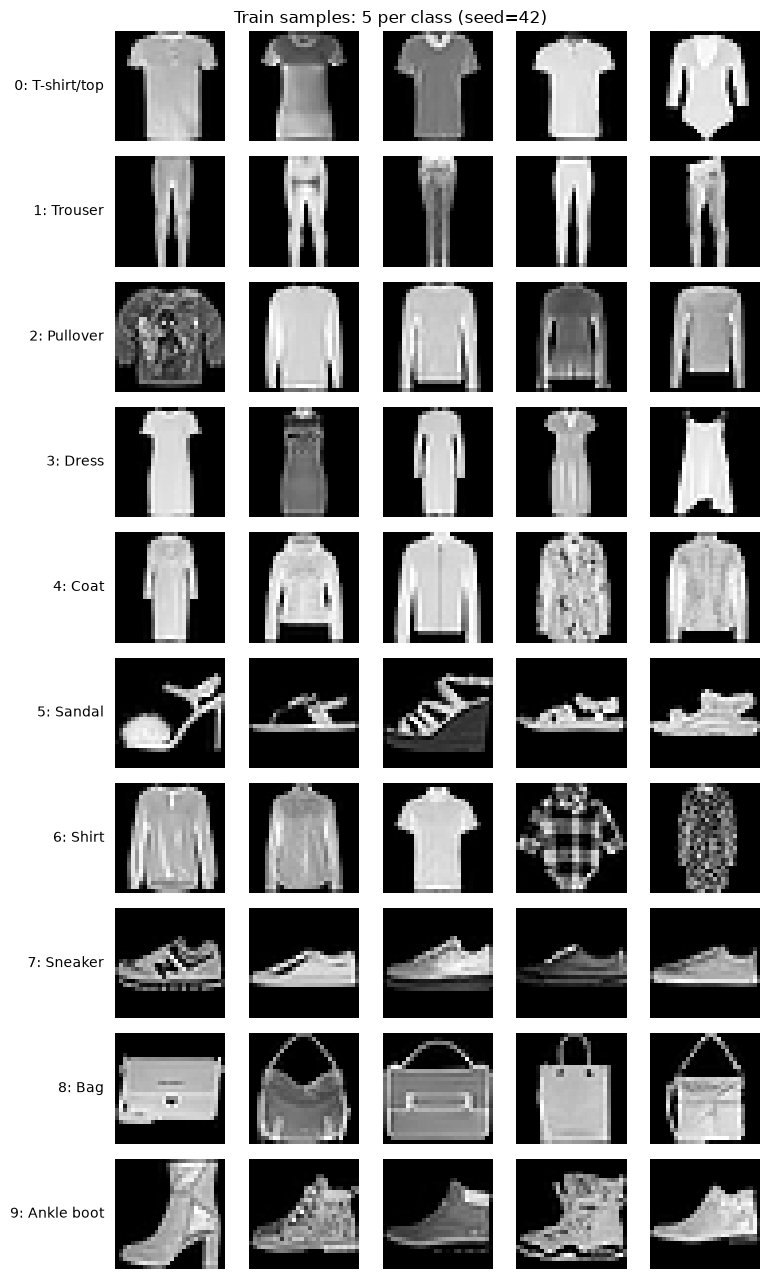

In [5]:
# 5-1. 설정값
N_SAMPLES_PER_CLASS = 5   # 클래스마다 보여줄 이미지 수
SEED = 42                 # 랜덤 시드: 실행할 때마다 같은 이미지가 뽑히도록 고정

rng = np.random.default_rng(SEED)

# 5-2. 그림판 만들기: 10줄(클래스) x 5칸(이미지)
fig, axes = plt.subplots(
    num_classes, N_SAMPLES_PER_CLASS,
    figsize=(N_SAMPLES_PER_CLASS * 1.3 + 1.5, num_classes * 1.3),
)

for class_idx, class_name in enumerate(class_names):
    # 5-3. 이 클래스에 속하는 이미지들의 위치(인덱스) 찾기
    #  - train_labels는 셀 4에서 꺼낸 학습 데이터의 targets 값입니다.
    class_indices = np.where(train_labels == class_idx)[0]

    # 5-4. 그중 N장을 중복 없이 무작위로 선택
    chosen = rng.choice(class_indices, size=N_SAMPLES_PER_CLASS, replace=False)

    for col, img_idx in enumerate(chosen):
        ax = axes[class_idx, col]

        # 5-5. data 속성에 저장된 이미지를 흑백으로 표시
        #  - vmin/vmax를 0~255로 고정해서 모든 이미지의 밝기 기준을 똑같이 맞춥니다.
        img = train_dataset.data[img_idx].numpy()
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)

        # 눈금과 테두리 제거 (이미지만 보이도록)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

    # 5-6. 각 줄 맨 왼쪽에 클래스 번호와 이름 표시
    axes[class_idx, 0].set_ylabel(
        f"{class_idx}: {class_name}",
        rotation=0, ha="right", va="center", fontsize=10, labelpad=8,
    )

fig.suptitle(f"Train samples: {N_SAMPLES_PER_CLASS} per class (seed={SEED})", fontsize=12)
plt.tight_layout()
plt.show()

### 결과
클래스마다 5장씩만 본 결과이므로, 아래 내용은 이 샘플에서 관찰한 것입니다.
아래에서 'n번째'는 각 줄의 왼쪽부터 센 순서입니다.

- 옷 종류마다 어떻게 생겼는가?
  - 배경은 검은색이고, 물건은 배경보다 밝은 회색~흰색으로 표시됩니다.
  - 모든 이미지에 물건이 하나씩, 가운데에 크게 놓여 있습니다.
  - 옷(T-shirt/top, Trouser, Pullover, Dress, Coat, Shirt)과 Bag은 앞에서 본 모습입니다.
  - 신발(Sandal, Sneaker, Ankle boot)은 옆에서 본 모습이고, 15장 모두 앞코가 왼쪽을 향합니다.
- 서로 헷갈릴 만한 비슷한 종류가 있는가?
  - 긴팔 상의인 Pullover(2, 3, 5번째), Coat(3, 5번째), Shirt(1, 2번째)는 전체 윤곽이 서로 비슷합니다.
  - Shirt 3번째는 반팔이라 T-shirt/top(1~4번째)과 윤곽이 비슷합니다.
  - Coat 1번째는 길이가 길어 Dress 3번째와 윤곽이 비슷합니다.
- 같은 종류 안에서도 모양이 얼마나 다양한가?
  - 무늬: Pullover 1번째, Coat 4번째, Shirt 4, 5번째는 무늬가 있고, 같은 줄의 다른 이미지는 무늬가 거의 없습니다.
  - 밝기: Trouser 3번째, Dress 2번째, Sneaker 4번째는 같은 줄의 다른 이미지보다 어둡습니다.
  - 모양:
    - T-shirt/top: 1~4번째는 반팔이고, 5번째는 긴팔에 아랫단이 뾰족합니다.
    - Dress: 반팔(1, 4번째), 긴팔(3번째), 어깨끈 형태(5번째)로 소매 모양이 다릅니다.
    - Sandal: 굽이 높은 것(1번째), 밑창이 두꺼운 것(3번째), 납작한 것(2, 4, 5번째)이 섞여 있습니다.
    - Bag: 손잡이가 보이지 않는 것(1번째)과 손잡이나 끈이 달린 것(2~5번째)이 섞여 있습니다.
    - Ankle boot: 굽이 높은 것(1번째)과 굽이 낮은 것(2~5번째)이 섞여 있습니다.

### 해석
- 각 줄의 이미지가 왼쪽에 적힌 클래스 이름에 해당하는 물건으로 보입니다. 셀 4에서 사용한 `targets` 값이 실제 이미지의 클래스 번호와 맞는다는 것을 눈으로 확인했습니다.
- 5장만 본 결과이므로, 위의 관찰이 데이터 전체에도 해당하는지는 이 셀만으로는 알 수 없습니다.